# In this notebook, we:
1. Clean the customer feedback text.
2. Convert text into numerical features using TF-IDF.
3. Train classification models for **Sentiment**, **Complaint Type**, and **Priority** (baseline).
4. Evaluate using Accuracy, Precision, Recall, F1-score, Cross-Validation, and Confusion Matrices.
5. Tune hyperparameters with `GridSearchCV`.
6. Save trained pipelines into `../models/`.

In [1]:
import re
import string
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Text Cleaning Function

In [2]:
def clean_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = pd.read_csv("../data/customer_feedback.csv")
df["clean_text"] = df["feedback_text"].apply(clean_text)

df[["feedback_text", "clean_text"]].head()

,feedback_text,clean_text
0,Everything worked out well in the end. The bil...,everything worked out well in the end the bill...
1,I had a good experience with the team. The sup...,i had a good experience with the team the supp...
2,"Overall, I am satisfied with the experience. T...",overall i am satisfied with the experience the...
3,Everything worked out well in the end. The cou...,everything worked out well in the end the cour...
4,I expected much better service. I received unc...,i expected much better service i received uncl...


## Train / Test Split

In [3]:
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["priority"]
)
print("Train size:", train_df.shape, "Test size:", test_df.shape)

Train size: (24000, 10) Test size: (6000, 10)


## Task 1: Sentiment Analysis (NLP + Logistic Regression + GridSearchCV)

In [4]:
# Compare Multinomial Naive Bayes vs Logistic Regression using Cross-Validation
nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=3000, ngram_range=(1, 2))),
    ("model", MultinomialNB())
])
nb_scores = cross_val_score(nb_pipeline, train_df["clean_text"], train_df["sentiment"], cv=5, scoring="accuracy")
print("Naive Bayes 5-Fold CV Accuracy:", round(nb_scores.mean(), 4))

# Hyperparameter tuning with GridSearchCV on Logistic Regression
sentiment_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid = {
    "tfidf__max_features": [2000, 3000],
    "model__C": [0.5, 1.0, 2.0]
}

grid_sent = GridSearchCV(sentiment_pipeline, param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid_sent.fit(train_df["clean_text"], train_df["sentiment"])

best_sentiment_model = grid_sent.best_estimator_
print("Best Sentiment Parameters:", grid_sent.best_params_)

Naive Bayes 5-Fold CV Accuracy: 1.0
Best Sentiment Parameters: {'model__C': 0.5, 'tfidf__max_features': 2000}


Sentiment Test Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

    Negative       1.00      1.00      1.00      2522
     Neutral       1.00      1.00      1.00      1281
    Positive       1.00      1.00      1.00      2197

    accuracy                           1.00      6000
   macro avg       1.00      1.00      1.00      6000
weighted avg       1.00      1.00      1.00      6000



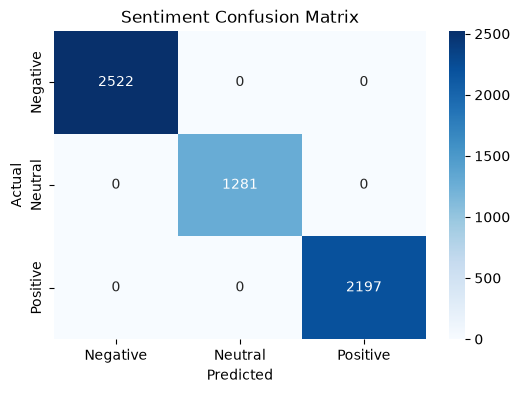

In [5]:
# Evaluate Sentiment Model on Test Set
y_pred_sent = best_sentiment_model.predict(test_df["clean_text"])
print("Sentiment Test Accuracy:", round(accuracy_score(test_df["sentiment"], y_pred_sent), 4))
print("\nClassification Report:\n", classification_report(test_df["sentiment"], y_pred_sent))

# Confusion Matrix
cm = confusion_matrix(test_df["sentiment"], y_pred_sent, labels=["Negative", "Neutral", "Positive"])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Sentiment Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Task 2: Complaint Type Classification (NLP + Logistic Regression)

Complaint Type 5-Fold CV Accuracy: 1.0
Complaint Type Test Accuracy: 1.0

Classification Report:
                    precision    recall  f1-score   support

          Billing       1.00      1.00      1.00       615
 Customer Service       1.00      1.00      1.00       834
         Delivery       1.00      1.00      1.00      1097
        Packaging       1.00      1.00      1.00       423
          Pricing       1.00      1.00      1.00       417
  Product Quality       1.00      1.00      1.00      1166
Returns & Refunds       1.00      1.00      1.00       595
  Technical Issue       1.00      1.00      1.00       853

         accuracy                           1.00      6000
        macro avg       1.00      1.00      1.00      6000
     weighted avg       1.00      1.00      1.00      6000



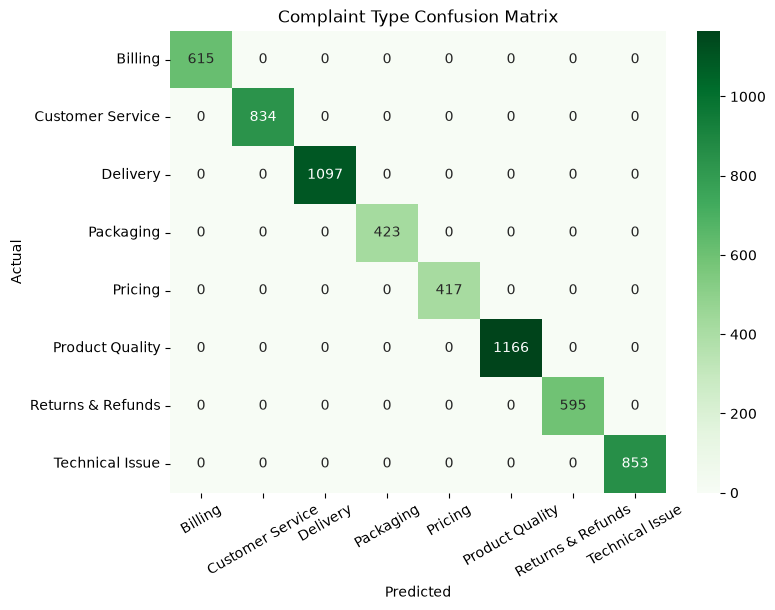

In [6]:
complaint_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=3000, ngram_range=(1, 2))),
    ("model", LogisticRegression(max_iter=1000))
])

comp_cv = cross_val_score(complaint_pipeline, train_df["clean_text"], train_df["complaint_type"], cv=5, scoring="accuracy")
print("Complaint Type 5-Fold CV Accuracy:", round(comp_cv.mean(), 4))

complaint_pipeline.fit(train_df["clean_text"], train_df["complaint_type"])
y_pred_comp = complaint_pipeline.predict(test_df["clean_text"])

print("Complaint Type Test Accuracy:", round(accuracy_score(test_df["complaint_type"], y_pred_comp), 4))
print("\nClassification Report:\n", classification_report(test_df["complaint_type"], y_pred_comp))

labels = sorted(df["complaint_type"].unique())
cm_comp = confusion_matrix(test_df["complaint_type"], y_pred_comp, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_comp, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("Complaint Type Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=30)
plt.show()

## Task 3: Priority Prediction (Traditional ML Baseline)

Priority Baseline (Logistic Regression) Accuracy: 0.4808

Classification Report:
               precision    recall  f1-score   support

        High       0.51      0.62      0.56      1980
         Low       0.50      0.62      0.55      2040
      Medium       0.37      0.19      0.25      1980

    accuracy                           0.48      6000
   macro avg       0.46      0.48      0.45      6000
weighted avg       0.46      0.48      0.46      6000



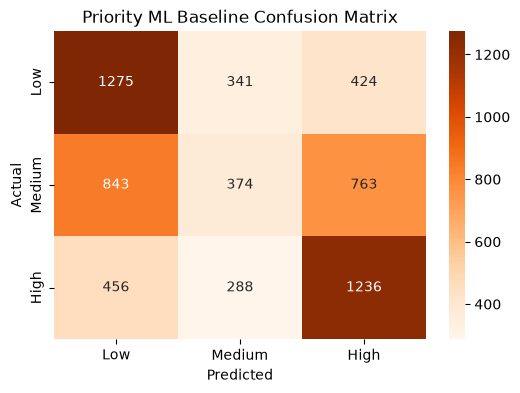

In [7]:
# Combine TF-IDF text features with scaled numerical & encoded categorical features
feature_cols = ["clean_text", "channel", "customer_type", "order_value", "days_as_customer"]

preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(max_features=2000, ngram_range=(1, 2)), "clean_text"),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["channel", "customer_type"]),
    ("num", StandardScaler(), ["order_value", "days_as_customer"])
])

priority_ml_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

priority_ml_pipeline.fit(train_df[feature_cols], train_df["priority"])
y_pred_prio = priority_ml_pipeline.predict(test_df[feature_cols])

print("Priority Baseline (Logistic Regression) Accuracy:", round(accuracy_score(test_df["priority"], y_pred_prio), 4))
print("\nClassification Report:\n", classification_report(test_df["priority"], y_pred_prio))

cm_prio = confusion_matrix(test_df["priority"], y_pred_prio, labels=["Low", "Medium", "High"])
plt.figure(figsize=(6, 4))
sns.heatmap(cm_prio, annot=True, fmt="d", cmap="Oranges", xticklabels=["Low", "Medium", "High"], yticklabels=["Low", "Medium", "High"])
plt.title("Priority ML Baseline Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Save Trained Pipelines

In [8]:
joblib.dump(best_sentiment_model, "../models/sentiment_pipeline.pkl")
joblib.dump(complaint_pipeline, "../models/complaint_model.pkl")
joblib.dump(priority_ml_pipeline, "../models/priority_ml_baseline.pkl")

print("Saved sentiment_pipeline.pkl, complaint_model.pkl, and priority_ml_baseline.pkl successfully!")

Saved sentiment_pipeline.pkl, complaint_model.pkl, and priority_ml_baseline.pkl successfully!
